<a href="https://colab.research.google.com/github/Njeri-Kiarie/Final_Capstone/blob/main/Salama_DistilBERT_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
# Verifying the selected GPU is available
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [45]:
# Uploading the prepared datasets
from google.colab import files

uploaded = files.upload()

Saving dev_chunks_cleaned.json to dev_chunks_cleaned (2).json
Saving test_chunks_cleaned.json to test_chunks_cleaned (2).json
Saving train_chunks.json to train_chunks (2).json


In [82]:
# Verify the upload
import os

for filename in [
    "train_chunks.json",
    "dev_chunks_cleaned (2).json",
    "test_chunks_cleaned (2).json"
]:
    print(filename, ":", os.path.exists(filename))

train_chunks.json : True
dev_chunks_cleaned (2).json : True
test_chunks_cleaned (2).json : True


In [85]:
# Loading the JSON datasets
import pandas as pd

# Load the prepared datasets
train_chunks = pd.read_json("train_chunks.json")
dev_chunks = pd.read_json("dev_chunks_cleaned (2).json")
test_chunks_df = pd.read_json("test_chunks_cleaned (2).json")

# Check their shapes
print("Training:", train_chunks.shape)
print("Development:", dev_chunks.shape)
print("Testing:", test_chunks_df.shape)

# Check available columns
print("\nColumns:")
print(train_chunks.columns.tolist())

Training: (3255, 6)
Development: (328, 6)
Testing: (504, 6)

Columns:
['narrative_id', 'input_ids', 'gbv_related', 'gbv_type_labels', 'gbv_event_status', 'status_label']


A pytorch dataset allows us to retrieve individual text chunks and their corresponding labels during model training.

In [86]:
# Creating the custom pytorch dataset
import torch
from torch.utils.data import Dataset

class GBVDataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        return {
            "input_ids": torch.tensor(
                row["input_ids"], dtype=torch.long
            ),
            "gbv_related": torch.tensor(
                row["gbv_related"], dtype=torch.float32
            ),
            "gbv_type_labels": torch.tensor(
                row["gbv_type_labels"], dtype=torch.float32
            ),
            "status_label": torch.tensor(
                row["status_label"], dtype=torch.long
            ),
            "narrative_id": row["narrative_id"]
        }

In [87]:
# Creating and verifying the pytorch dataset objects
# Create PyTorch datasets
train_dataset = GBVDataset(train_chunks)
dev_dataset = GBVDataset(dev_chunks)
test_dataset = GBVDataset(test_chunks_df)

# Check dataset sizes
print("Training samples:", len(train_dataset))
print("Development samples:", len(dev_dataset))
print("Testing samples:", len(test_dataset))

# Inspect one training sample
sample = train_dataset[0]

print("\nSample input shape:", sample["input_ids"].shape)
print("Binary GBV label:", sample["gbv_related"])
print("GBV type labels:", sample["gbv_type_labels"])
print("Temporal label:", sample["status_label"])
print("Narrative ID:", sample["narrative_id"])

Training samples: 3255
Development samples: 328
Testing samples: 504

Sample input shape: torch.Size([211])
Binary GBV label: tensor(1.)
GBV type labels: tensor([1., 0., 0., 0.])
Temporal label: tensor(1)
Narrative ID: Question 2


All training, development and testing chunks have successfully loaded. The sample contains 211 tokens, the narrative is gbv related, Domestic violence is the only GBV category identified and is ongoing.

Since our narratives have different token lengths, Pytorch cannot combine sequences of different lenghts into a single tensor. We therefore use dynamic padding which pads each batch only to the length of its longest sequence.

In [88]:
# Creating the collate_fn for dynamic padding
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):

    # Pad token sequences to the longest sequence in the batch
    input_ids = pad_sequence(
        [item["input_ids"] for item in batch],
        batch_first=True,
        padding_value=0
    )

    # Attention mask: 1 for actual tokens, 0 for padding
    attention_mask = (input_ids != 0).long()

    # Combine classification labels
    gbv_related = torch.stack([
        item["gbv_related"] for item in batch
    ])

    gbv_type_labels = torch.stack([
        item["gbv_type_labels"] for item in batch
    ])

    status_labels = torch.stack([
        item["status_label"] for item in batch
    ])

    narrative_ids = [
        item["narrative_id"] for item in batch
    ]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "gbv_related": gbv_related,
        "gbv_type_labels": gbv_type_labels,
        "status_label": status_labels,
        "narrative_id": narrative_ids
    }

We also use the attention mask to distinguish actual tokens from padding tokens. Hence the model will ignore padding positions when calculating attention.

Dataloaders then organise our data into batches and make it easier to train and evaluate DistilBert

In [89]:
# Creating the dataloaders
from torch.utils.data import DataLoader

batch_size = 8

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

# Development DataLoader
dev_loader = DataLoader(
    dev_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

# Test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

# Check number of batches
print("Training batches:", len(train_loader))
print("Development batches:", len(dev_loader))
print("Testing batches:", len(test_loader))

Training batches: 407
Development batches: 41
Testing batches: 63


We use `shuffle=True` during training since it changes the order in which the model encounters examples helping to reduce order bias.

We use `shuffle=False` for development and testing to keep predictions in a consistent order which makes it easier to aggregate chunk predictions using their `narrative_id`

Before training DistilBert, we verify that the DataLoader correctly combines the tokenized text, attention masks and classification labels

In [90]:
# Inspecting one training batch
# Retrieve one batch from the training DataLoader
batch = next(iter(train_loader))

print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)

print("\nBinary GBV labels shape:", batch["gbv_related"].shape)
print("GBV type labels shape:", batch["gbv_type_labels"].shape)
print("Temporal labels shape:", batch["status_label"].shape)

print("\nNarrative IDs:", batch["narrative_id"])

# Confirm no sequence exceeds DistilBERT's maximum length
print("\nMaximum sequence length:", batch["input_ids"].shape[1])

Input IDs shape: torch.Size([8, 350])
Attention mask shape: torch.Size([8, 350])

Binary GBV labels shape: torch.Size([8])
GBV type labels shape: torch.Size([8, 4])
Temporal labels shape: torch.Size([8])

Narrative IDs: ['Question 405', 'Question 3738', 'Question 3936', 'Question 3073', 'Question 4053', 'Question 2281', 'Question 1191', 'Question 2519']

Maximum sequence length: 350


We'll begin with our first task; predicting whether a narrative is GBV-related or not i.e: (1) or (0)

In [91]:
# Loading DistilBert for GBV binary classification
from transformers import AutoModelForSequenceClassification
import torch

# Select GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained DistilBERT
binary_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=1
)

# Move model to GPU
binary_model = binary_model.to(device)

print("Device:", device)
print("Model loaded successfully!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Model loaded successfully!


In [92]:
# Configuring the binary classifier's loss function and optimizer
import torch.nn as nn
from torch.optim import AdamW

# Calculate binary positive class weight from training narratives
positive_count = train_chunks.drop_duplicates("narrative_id")["gbv_related"].sum()
negative_count = train_chunks["narrative_id"].nunique() - positive_count

binary_pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32,
    device=device
)

# Binary classification loss
binary_loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=binary_pos_weight
)

# Optimizer
binary_optimizer = AdamW(
    binary_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("Binary positive weight:", binary_pos_weight.item())
print("Learning rate:", binary_optimizer.param_groups[0]["lr"])
print("Loss function:", binary_loss_fn)

Binary positive weight: 1.4017502069473267
Learning rate: 2e-05
Loss function: BCEWithLogitsLoss()


The positive class weight means that misclassifying a GBV-positive example contributes approximately 1.4 times as much positive-class loss as it would without weighting.

In [93]:
# Configuring the training settings
from transformers import get_linear_schedule_with_warmup

# Training configuration
num_epochs = 3

# Total optimizer update steps
total_training_steps = len(train_loader) * num_epochs

# Learning-rate scheduler
binary_scheduler = get_linear_schedule_with_warmup(
    binary_optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

print("Number of epochs:", num_epochs)
print("Training batches per epoch:", len(train_loader))
print("Total training steps:", total_training_steps)
print("Warmup steps:", int(0.1 * total_training_steps))

Number of epochs: 3
Training batches per epoch: 407
Total training steps: 1221
Warmup steps: 122


In [94]:
# Creating the binary classifier training function
from tqdm.auto import tqdm

def train_binary_epoch(model, dataloader, optimizer, scheduler, loss_fn, device):

    model.train()
    total_loss = 0

    progress_bar = tqdm(dataloader, desc="Training")

    for batch in progress_bar:

        # Move inputs and labels to GPU
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["gbv_related"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # One prediction per chunk
        logits = outputs.logits.squeeze(-1)

        # Calculate binary classification loss
        loss = loss_fn(logits, labels)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model parameters
        optimizer.step()
        scheduler.step()

        # Track training loss
        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / len(dataloader)

The function:
1. Sets DistilBERT to training mode using model.train()
2. Process each batch of 8 text chunks on the GPU.
3. Generate one GBV Classification logit per chunk.
4. Calculate the weighted binary cross-entropy loss.
5. Update the model parameters through backpropagation.

Evaluating how well Salama identifies GBV-related narratives during training.

In [95]:
# Creating the binary classification validation function
import numpy as np
import pandas as pd
import torch

def validate_binary(model, dataloader, loss_fn, device):

    model.eval()
    total_loss = 0
    all_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["gbv_related"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits.squeeze(-1)
            loss = loss_fn(logits, labels)

            total_loss += loss.item()

            # Convert logits into probabilities
            probabilities = torch.sigmoid(logits).cpu().numpy()

            for narrative_id, probability, label in zip(
                batch["narrative_id"],
                probabilities,
                labels.cpu().numpy()
            ):
                all_predictions.append({
                    "narrative_id": narrative_id,
                    "probability": float(probability),
                    "actual": int(label)
                })

    # Aggregate chunk predictions into narrative predictions
    predictions_df = pd.DataFrame(all_predictions)

    narrative_predictions = predictions_df.groupby(
        "narrative_id", as_index=False
    ).agg(
        probability=("probability", "mean"),
        actual=("actual", "first")
    )

    # Apply classification threshold
    narrative_predictions["predicted"] = (
        narrative_predictions["probability"] >= 0.5
    ).astype(int)

    y_true = narrative_predictions["actual"].to_numpy()
    y_pred = narrative_predictions["predicted"].to_numpy()

    # Calculate evaluation metrics
    accuracy = np.mean(y_true == y_pred)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    return {
        "loss": total_loss / len(dataloader),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

Training the first training experiment for 3 epochs while evaluating the model on the development dataset after each epoch.

In [96]:
# Training and Validating DistilBERT
# Store training history
binary_history = []

best_f1 = -1.0

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 40)

    # Train for one epoch
    train_loss = train_binary_epoch(
        binary_model,
        train_loader,
        binary_optimizer,
        binary_scheduler,
        binary_loss_fn,
        device
    )

    # Evaluate on development data
    val_metrics = validate_binary(
        binary_model,
        dev_loader,
        binary_loss_fn,
        device
    )

    # Save results
    binary_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "accuracy": val_metrics["accuracy"],
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "f1": val_metrics["f1"]
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Precision: {val_metrics['precision']:.4f}")
    print(f"Recall: {val_metrics['recall']:.4f}")
    print(f"F1 Score: {val_metrics['f1']:.4f}")

    # Save the best model based on validation F1
    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]

        binary_model.save_pretrained(
            "salama_binary_best"
        )

        print("Best model saved!")

# Display training history
binary_results = pd.DataFrame(binary_history)

display(binary_results)


Epoch 1/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.3678
Validation Loss: 0.2903
Accuracy: 0.9580
Precision: 0.9286
Recall: 0.9750
F1 Score: 0.9512


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Epoch 2/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.1309
Validation Loss: 0.3008
Accuracy: 0.9441
Precision: 0.8939
Recall: 0.9833
F1 Score: 0.9365

Epoch 3/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.0586
Validation Loss: 0.3098
Accuracy: 0.9510
Precision: 0.9077
Recall: 0.9833
F1 Score: 0.9440


,epoch,train_loss,val_loss,accuracy,precision,recall,f1
0,1,0.367837,0.290291,0.958042,0.928571,0.975000,0.951220
1,2,0.130930,0.300790,0.944056,0.893939,0.983333,0.936508
2,3,0.058587,0.309785,0.951049,0.907692,0.983333,0.944000


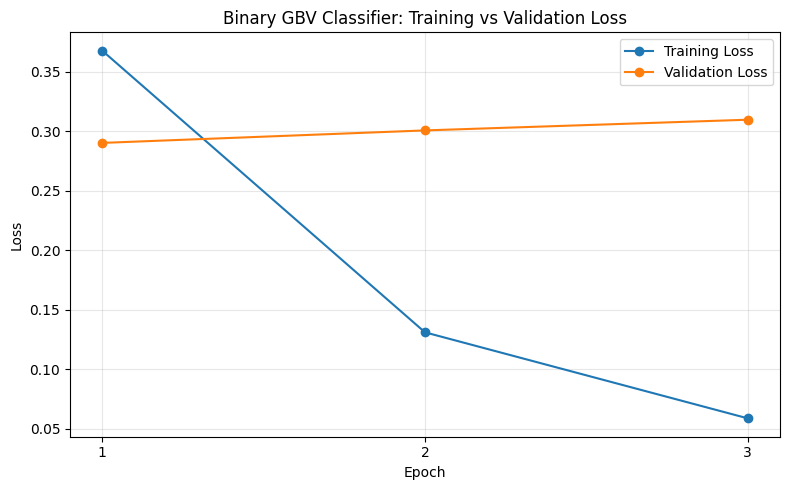

In [97]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    binary_results["epoch"],
    binary_results["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    binary_results["epoch"],
    binary_results["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Binary GBV Classifier: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(binary_results["epoch"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Training loss decreased consistently across the three epochs, indicating that the DistilBERT model was learning patterns from the training data.

However, validation loss increased slightly from 0.2903 in Epoch 1 to 0.3098 in Epoch 3, suggesting possible overfitting as training progressed.

Epoch 1 achieved the lowest validation loss and the highest validation F1-score of 95.12%. Therefore, Epoch 1 was selected as the best checkpoint to reduce overfitting and improve generalization.

In [98]:
# Examining the confusion matrix
from transformers import AutoModelForSequenceClassification

# Reload the best model (Epoch 3)
best_binary_model = AutoModelForSequenceClassification.from_pretrained(
    "salama_binary_best"
).to(device)

best_binary_model.eval()

# Get validation predictions
all_predictions = []

with torch.no_grad():
    for batch in dev_loader:
        outputs = best_binary_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        probabilities = torch.sigmoid(
            outputs.logits.squeeze(-1)
        ).cpu().numpy()

        for narrative_id, probability, actual in zip(
            batch["narrative_id"],
            probabilities,
            batch["gbv_related"].numpy()
        ):
            all_predictions.append({
                "narrative_id": narrative_id,
                "probability": float(probability),
                "actual": int(actual)
            })

# Aggregate predictions at narrative level
validation_predictions = (
    pd.DataFrame(all_predictions)
    .groupby("narrative_id", as_index=False)
    .agg(
        probability=("probability", "mean"),
        actual=("actual", "first")
    )
)

validation_predictions["predicted"] = (
    validation_predictions["probability"] >= 0.5
).astype(int)

# Calculate confusion matrix counts
tn = ((validation_predictions["actual"] == 0) &
      (validation_predictions["predicted"] == 0)).sum()

fp = ((validation_predictions["actual"] == 0) &
      (validation_predictions["predicted"] == 1)).sum()

fn = ((validation_predictions["actual"] == 1) &
      (validation_predictions["predicted"] == 0)).sum()

tp = ((validation_predictions["actual"] == 1) &
      (validation_predictions["predicted"] == 1)).sum()

print("Confusion Matrix:")
print([[tn, fp], [fn, tp]])

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Confusion Matrix:
[[np.int64(157), np.int64(9)], [np.int64(3), np.int64(117)]]

True Negatives: 157
False Positives: 9
False Negatives: 3
True Positives: 117


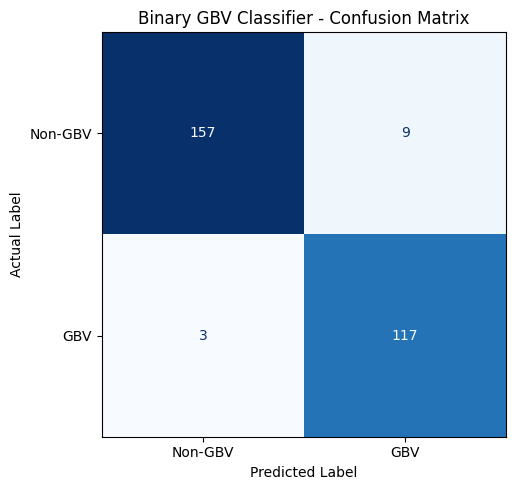

In [99]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Create confusion matrix
cm = np.array([[tn, fp],
               [fn, tp]])

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-GBV", "GBV"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Binary GBV Classifier - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [100]:
# Examining the misclassified narratives
# Extract incorrectly classified narratives
misclassified = validation_predictions[
    validation_predictions["actual"] !=
    validation_predictions["predicted"]
].copy()

# Identify the error type
misclassified["error_type"] = misclassified.apply(
    lambda row: "False Negative"
    if row["actual"] == 1
    else "False Positive",
    axis=1
)

display(
    misclassified[
        ["narrative_id", "actual", "predicted",
         "probability", "error_type"]
    ].sort_values("error_type")
)

,narrative_id,actual,predicted,probability,error_type
31,Question 13,1,0,0.388755,False Negative
110,Question 233,1,0,0.347098,False Negative
140,Question 288,1,0,0.011035,False Negative
11,Question 109,0,1,0.991043,False Positive
15,Question 112,0,1,0.986857,False Positive
23,Question 120,0,1,0.989593,False Positive
103,Question 226,0,1,0.990047,False Positive
149,Question 299,0,1,0.949058,False Positive
178,Question 337,0,1,0.937770,False Positive
180,Question 341,0,1,0.886343,False Positive


In [102]:
# Investigating the original narratives
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

# Examine the false negative
false_negative_ids = ["Question 13", "Question 233", "Question 288"]

for narrative_id in false_negative_ids:

    chunks = dev_chunks[
        dev_chunks["narrative_id"] == narrative_id
    ]

    print(f"\n{'=' * 60}")
    print("Narrative:", narrative_id)
    print("Number of chunks:", len(chunks))
    print("GBV type labels:", chunks.iloc[0]["gbv_type_labels"])
    print("Temporal status:", chunks.iloc[0]["gbv_event_status"])

    for i, token_ids in enumerate(chunks["input_ids"], start=1):
        text = tokenizer.decode(
            token_ids,
            skip_special_tokens=True
        )

        print(f"\nChunk {i}:")
        print(text)


Narrative: Question 13
Number of chunks: 3
GBV type labels: [1, 0, 0, 0]
Temporal status: past

Chunk 1:
don ' t tell me : an open letter to the mutual friends & family who will not see this. i left an increasingly abusive & violent relationship of well over a decade some months ago, and still have a large number of mutual friends / family who don ' t really know why or what happened. i can ' t actually talk to them about it, but i ' m increasingly bothered by some of their responses so i made an account to post some thoughts somewhere. it ' s silly but i just need this to exist in the world somewhere, rather than entirely in my head. feel free to pass right on by this ; mild trigger warning if you don ' t. it wasn ' t once. it wasn ' t sudden. and i ' m not mistaken. it was pervasive, and subtle, and obvious, and horrible, and specifically designed to keep things exactly as they were. some have it worse, some not so much, but none deserved it. there is nothing a person can do to warr

The binary GBV classifier produced three false negatives during evaluation on the cleaned development dataset.

**Question 13 (Domestic Violence):** The narrative described a long-term abusive relationship involving physical and psychological violence. Because the narrative was divided into three overlapping chunks, averaging chunk-level probabilities may have contributed to the incorrect classification.

**Question 233 (Sexual Assault):** The narrative contained a brief sexual assault disclosure within a broader discussion of suicidal thoughts, self-harm and mental health challenges. The model may have placed greater emphasis on the dominant mental health-related content.

**Question 288 (Sexual Assault):** The narrative described past rape using censored terminology such as "r @ pe" and "r * ped". The model may have struggled to recognize these obfuscated expressions.

These errors suggest that the classifier may have difficulty identifying GBV disclosures in lengthy narratives, narratives involving multiple crises, and text containing censored terminology. Further analysis of prediction probabilities is required to confirm the underlying causes.

In [103]:
# Examining the false positives
false_positive_ids = misclassified.loc[
    misclassified["error_type"] == "False Positive",
    "narrative_id"
].tolist()

for narrative_id in false_positive_ids:

    chunks = dev_chunks[
        dev_chunks["narrative_id"] == narrative_id
    ]

    print(f"\n{'=' * 60}")
    print("Narrative:", narrative_id)
    print("GBV type labels:", chunks.iloc[0]["gbv_type_labels"])
    print("Temporal status:", chunks.iloc[0]["gbv_event_status"])

    for i, token_ids in enumerate(chunks["input_ids"], start=1):
        print(f"\nChunk {i}:")
        print(tokenizer.decode(token_ids, skip_special_tokens=True))


Narrative: Question 109
GBV type labels: [0, 0, 0, 0]
Temporal status: not_applicable

Chunk 1:
who else feels like they ' re only still living to spare the feelings of their family members? there ' s nothing in my life worth living for anymore. everything and everyone who brought any join into my life is gone. i ' m disabled, in poor health, i suffer abuse on a daily basis and i feel totally alone in this world. it would be a relief to be able to just stop existing. the only thing preventing me is the fact that i have 1 or 2 family members who i feel would be deeply affected if i were to check out on them. so i suffer through each day more alone then the last in order to spare their feelings. anyone else in a similar situation?

Narrative: Question 112
GBV type labels: [0, 0, 0, 0]
Temporal status: not_applicable

Chunk 1:
hopefully my finale lmao. i made a plan, just choosing a date, early next year i ' m thinking, i ' m gonna give away stuff then call someone to grab my body and de

The binary GBV classifier produced nine false positives during evaluation on the development dataset.

Manual examination revealed three patterns. First, some narratives described experiences of physical abuse, sexual assault or family violence despite being labelled as non-GBV, suggesting possible annotation inconsistencies. Second, some narratives contained ambiguous references to abuse without sufficient context to confirm GBV. Third, several narratives focused on other forms of distress, including financial difficulties, self-harm and online bullying, without clear GBV disclosures.

These findings suggest that some false positives may result from incomplete or ambiguous annotations, while others may reflect the model's difficulty distinguishing GBV-related content from other crisis narratives.

**Multilabel GBV Classification**

DistilBERT model will identify which types of GBV are present in a narrative.

Unlike binary classification, a narrative can belong to more than one category.

We'll use four output neurons with sigmoid activation, allowing each category to receive an independent probability.

In [104]:
# Initializing the multilabel distilBERT model
from transformers import AutoModelForSequenceClassification

# Four GBV categories
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

# Initialize DistilBERT for multi-label classification
multilabel_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4,
    problem_type="multi_label_classification"
).to(device)

print("Number of GBV categories:", multilabel_model.config.num_labels)
print("Model device:", next(multilabel_model.parameters()).device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Number of GBV categories: 4
Model device: cuda:0


In [105]:
# Checking for class imbalance
import numpy as np
import pandas as pd

# Get one label vector per narrative
train_labels = (
    train_chunks
    .drop_duplicates(subset="narrative_id")
    ["gbv_type_labels"]
)

# Convert label vectors into a DataFrame
label_df = pd.DataFrame(
    train_labels.tolist(),
    columns=gbv_categories
)

# Count positive and negative examples
class_distribution = pd.DataFrame({
    "Positive": label_df.sum(),
    "Negative": len(label_df) - label_df.sum()
})

class_distribution["Positive (%)"] = (
    class_distribution["Positive"] / len(label_df) * 100
).round(2)

display(class_distribution)

,Positive,Negative,Positive (%)
domesticviolence,500,2519,16.56
rape,407,2612,13.48
sexualharassment,373,2646,12.36
childabuse_endangerment,182,2837,6.03


In [106]:
import torch
import torch.nn as nn

# Calculate positive weights for each GBV category
positive_weights = (
    class_distribution["Negative"] /
    class_distribution["Positive"]
)

# Convert weights to a tensor on the GPU
multilabel_pos_weight = torch.tensor(
    positive_weights.values,
    dtype=torch.float32,
    device=device
)

# Define the weighted loss function
multilabel_loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=multilabel_pos_weight
)

print("Positive class weights:")
for category, weight in zip(gbv_categories, multilabel_pos_weight):
    print(f"{category}: {weight.item():.4f}")

Positive class weights:
domesticviolence: 5.0380
rape: 6.4177
sexualharassment: 7.0938
childabuse_endangerment: 15.5879


In [107]:
# Setting up the optimizer and scheduler
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Number of training epochs
multilabel_epochs = 3

# Initialize optimizer
multilabel_optimizer = AdamW(
    multilabel_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# Calculate training steps
total_steps = len(train_loader) * multilabel_epochs

# Use 10% of training steps for warmup
warmup_steps = int(0.1 * total_steps)

# Initialize learning rate scheduler
multilabel_scheduler = get_linear_schedule_with_warmup(
    multilabel_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Training batches:", len(train_loader))
print("Epochs:", multilabel_epochs)
print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)

Training batches: 407
Epochs: 3
Total training steps: 1221
Warmup steps: 122


In [108]:
# Creating the multilabel training function
from tqdm.auto import tqdm
import torch

def train_multilabel_epoch(model, dataloader, optimizer, scheduler, loss_fn):

    model.train()
    total_loss = 0

    progress_bar = tqdm(dataloader, desc="Training")

    for batch in progress_bar:

        # Move inputs and labels to GPU
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["gbv_type_labels"].to(device).float()

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate weighted multi-label loss
        loss = loss_fn(outputs.logits, labels)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model weights
        optimizer.step()

        # Update learning rate
        scheduler.step()

        # Track training loss
        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / len(dataloader)

In [109]:
# Creating the multilabel validation function
from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score
)

import pandas as pd
import numpy as np
import torch

def validate_multilabel(model, dataloader, loss_fn):

    model.eval()

    total_loss = 0
    predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["gbv_type_labels"].to(device).float()

            # Forward pass
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Calculate validation loss
            loss = loss_fn(outputs.logits, labels)
            total_loss += loss.item()

            # Convert logits to probabilities
            probabilities = torch.sigmoid(
                outputs.logits
            ).cpu().numpy()

            # Store each chunk's predictions
            for narrative_id, probs, true_labels in zip(
                batch["narrative_id"],
                probabilities,
                labels.cpu().numpy()
            ):
                predictions.append({
                    "narrative_id": narrative_id,
                    "probabilities": probs,
                    "true_labels": true_labels
                })

    # Combine chunk predictions by narrative
    predictions_df = pd.DataFrame(predictions)

    narrative_results = (
        predictions_df.groupby("narrative_id")
        .agg({
            "probabilities": lambda x: np.mean(
                np.stack(x), axis=0
            ),
            "true_labels": "first"
        })
        .reset_index()
    )

    # Actual labels
    y_true = np.stack(
        narrative_results["true_labels"].values
    ).astype(int)

    # Predicted probabilities
    y_prob = np.stack(
        narrative_results["probabilities"].values
    )

    # Apply 0.5 threshold independently to each category
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate category-level metrics
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average=None,
            zero_division=0
        )
    )

    # Create category performance table
    category_metrics = pd.DataFrame({
        "Category": gbv_categories,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Support": support
    })

    # Overall macro F1
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    avg_loss = total_loss / len(dataloader)

    return avg_loss, macro_f1, category_metrics

In [110]:
# Train the multilabel GBV classifier
# Store training results
multilabel_history = []

# Track the best validation performance
best_macro_f1 = -1

for epoch in range(multilabel_epochs):

    print(f"\nEpoch {epoch + 1}/{multilabel_epochs}")

    # Train the model
    train_loss = train_multilabel_epoch(
        multilabel_model,
        train_loader,
        multilabel_optimizer,
        multilabel_scheduler,
        multilabel_loss_fn
    )

    # Evaluate on development data
    val_loss, macro_f1, category_metrics = validate_multilabel(
        multilabel_model,
        dev_loader,
        multilabel_loss_fn
    )

    # Save epoch results
    multilabel_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Validation Loss": val_loss,
        "Macro F1": macro_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")

    print("\nPerformance by GBV Category:")
    display(category_metrics.round(4))

    # Save best-performing model
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1

        multilabel_model.save_pretrained(
            "salama_multilabel_best"
        )

        print("Best model saved!")

# Display training history
multilabel_results = pd.DataFrame(multilabel_history)

print("\nTraining Summary:")
display(multilabel_results.round(4))


Epoch 1/3


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.8520
Validation Loss: 0.5785
Validation Macro F1: 0.5954

Performance by GBV Category:


,Category,Precision,Recall,F1 Score,Support
0,domesticviolence,0.6377,0.9778,0.7719,45
1,rape,0.6190,0.9512,0.7500,41
2,sexualharassment,0.5800,0.8788,0.6988,33
3,childabuse_endangerment,0.0886,0.8750,0.1609,8


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Training Loss: 0.3085
Validation Loss: 0.4846
Validation Macro F1: 0.6581

Performance by GBV Category:


,Category,Precision,Recall,F1 Score,Support
0,domesticviolence,0.6875,0.9778,0.8073,45
1,rape,0.6964,0.9512,0.8041,41
2,sexualharassment,0.7000,0.8485,0.7671,33
3,childabuse_endangerment,0.1455,1.0000,0.2540,8


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Training Summary:


,Epoch,Training Loss,Validation Loss,Macro F1
0,1,0.8520,0.5785,0.5954
1,2,0.4327,0.5586,0.5634
2,3,0.3085,0.4846,0.6581


The DistilBERT multi-label classifier was trained for **3 epochs** using the AdamW optimizer, a learning rate of `2e-5`, and weighted binary cross-entropy loss (`BCEWithLogitsLoss`) to address class imbalance.

Model performance was evaluated on the development dataset using **macro F1-score**, with predictions aggregated at the narrative level.

| Epoch | Training Loss | Validation Loss | Macro F1-Score |
|---|---|---|---|
| 1 | 0.8520 | 0.5785 | 0.5954 |
| 2 | 0.4327 | 0.5586 | 0.5634 |
| 3 | 0.3085 | 0.4846 | **0.6581** |

**Observations:**

- Training loss decreased consistently across all three epochs, indicating that the model was learning.
- Validation loss also decreased, suggesting improved performance on unseen development narratives.
- Macro F1-score decreased slightly in Epoch 2 before improving to **65.81% in Epoch 3**.
- Epoch 3 achieved the highest macro F1-score and lowest validation loss and was therefore selected as the best checkpoint.

In [111]:
# Loading the best model
from transformers import AutoModelForSequenceClassification

best_multilabel_model = (
    AutoModelForSequenceClassification.from_pretrained(
        "salama_multilabel_best"
    ).to(device)
)

best_multilabel_model.eval()

print("Best multi-label model loaded successfully!")
print("Device:", next(best_multilabel_model.parameters()).device)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best multi-label model loaded successfully!
Device: cuda:0


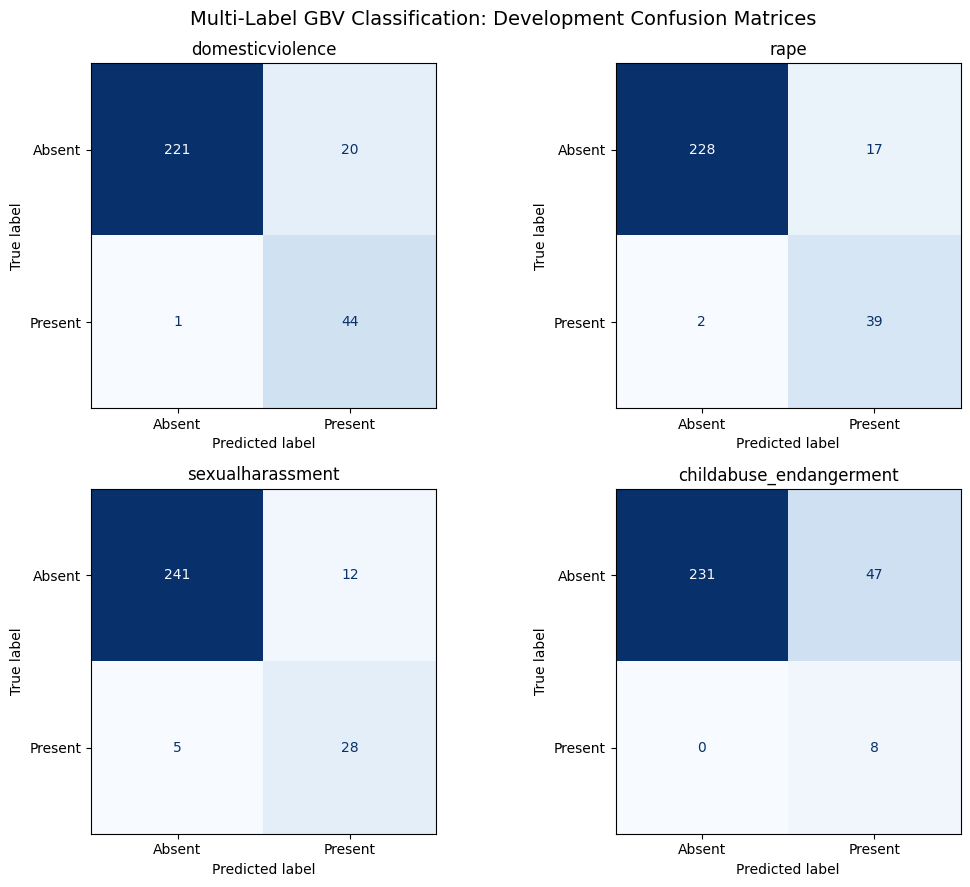

Narratives evaluated: 286


In [112]:
# Generating the confusion matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

best_multilabel_model.eval()

chunk_predictions = []

with torch.no_grad():
    for batch in dev_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = best_multilabel_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.sigmoid(
            outputs.logits
        ).cpu().numpy()

        for narrative_id, probs, labels in zip(
            batch["narrative_id"],
            probabilities,
            batch["gbv_type_labels"].cpu().numpy()
        ):
            chunk_predictions.append({
                "narrative_id": narrative_id,
                "probabilities": probs,
                "true_labels": labels
            })

# Aggregate predictions at narrative level
chunk_predictions_df = pd.DataFrame(chunk_predictions)

multilabel_dev_predictions = (
    chunk_predictions_df.groupby("narrative_id")
    .agg({
        "probabilities": lambda x: np.mean(
            np.stack(x), axis=0
        ),
        "true_labels": "first"
    })
    .reset_index()
)

# Actual labels and predicted probabilities
y_true = np.stack(
    multilabel_dev_predictions["true_labels"]
).astype(int)

y_prob = np.stack(
    multilabel_dev_predictions["probabilities"]
)

# Initial classification threshold
y_pred = (y_prob >= 0.5).astype(int)

# Plot four confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for i, category in enumerate(gbv_categories):

    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Absent", "Present"]
    )

    disp.plot(
        ax=axes.flat[i],
        cmap="Blues",
        colorbar=False
    )

    axes.flat[i].set_title(category)

plt.suptitle(
    "Multi-Label GBV Classification: Development Confusion Matrices",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Narratives evaluated:", len(multilabel_dev_predictions))

The best-performing DistilBERT model (Epoch 3) was evaluated on **286 development narratives** using a classification threshold of `0.5` for each GBV category.

Predictions from multiple chunks were averaged to obtain one prediction per narrative.

| GBV Category | True Positives | True Negatives | False Positives | False Negatives |
|---|---|---|---|---|
| Domestic Violence | 44 | 221 | 20 | 1 |
| Rape | 39 | 228 | 17 | 2 |
| Sexual Harassment | 28 | 241 | 12 | 5 |
| Child Abuse/Endangerment | 8 | 231 | 47 | 0 |

**Observations:**

- **Domestic Violence:** The model correctly identified 44 out of 45 positive cases, demonstrating high recall, although 20 false positives were recorded.
- **Rape:** The model correctly identified 39 out of 41 positive cases, with only 2 false negatives.
- **Sexual Harassment:** The model identified 28 out of 33 positive cases but missed 5, indicating room for improvement in recall.
- **Child Abuse/Endangerment:** The model identified all 8 positive cases, achieving 100% recall. However, it produced 47 false positives, resulting in very low precision (14.55%)

The model demonstrated strong recall across the four GBV categories but produced several false positives, particularly for child abuse/endangerment. This may be partly influenced by the high positive class weight assigned to the minority category.

In [113]:
# Examining different thresholds for the childabuse_endangerment
from sklearn.metrics import precision_score, recall_score, f1_score

# Child abuse is the fourth category
child_idx = gbv_categories.index("childabuse_endangerment")

child_true = y_true[:, child_idx]
child_probs = y_prob[:, child_idx]

threshold_results = []

for threshold in np.arange(0.1, 1.0, 0.05):

    child_pred = (child_probs >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            child_true, child_pred, zero_division=0
        ),
        "Recall": recall_score(
            child_true, child_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            child_true, child_pred, zero_division=0
        ),
        "Predicted Positives": child_pred.sum()
    })

child_threshold_df = pd.DataFrame(threshold_results)

display(child_threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score,Predicted Positives
0,0.10,0.0661,1.000,0.1240,121
1,0.15,0.0825,1.000,0.1524,97
2,0.20,0.0920,1.000,0.1684,87
3,0.25,0.1039,1.000,0.1882,77
4,0.30,0.1127,1.000,0.2025,71
5,0.35,0.1270,1.000,0.2254,63
6,0.40,0.1290,1.000,0.2286,62
7,0.45,0.1311,1.000,0.2319,61
8,0.50,0.1455,1.000,0.2540,55
9,0.55,0.1509,1.000,0.2623,53


In [114]:
# Identify child abuse category
child_idx = gbv_categories.index("childabuse_endangerment")

# Extract narrative IDs, actual labels and probabilities
child_analysis = pd.DataFrame({
    "narrative_id": multilabel_dev_predictions["narrative_id"],
    "actual_label": y_true[:, child_idx],
    "predicted_probability": y_prob[:, child_idx]
})

# Focus on actual child abuse cases
positive_cases = child_analysis[
    child_analysis["actual_label"] == 1
].copy()

# Compare predictions at different thresholds
for threshold in [0.60, 0.90, 0.95]:
    positive_cases[f"pred_{threshold}"] = (
        positive_cases["predicted_probability"] >= threshold
    ).astype(int)

display(
    positive_cases.sort_values("predicted_probability")
    .round(4)
)

,narrative_id,actual_label,predicted_probability,pred_0.6,pred_0.9,pred_0.95
204,Question 370,1,0.6009,1,0,0
182,Question 343,1,0.9033,1,1,0
255,Question 53,1,0.9593,1,1,1
53,Question 170,1,0.9661,1,1,1
247,Question 45,1,0.9675,1,1,1
210,Question 386,1,0.9683,1,1,1
211,Question 387,1,0.9687,1,1,1
126,Question 251,1,0.9699,1,1,1


In [117]:
# Examining the narratives with the false negatives when threshold is increased
cases_to_review = ["Question 370", "Question 343"]

for narrative_id in cases_to_review:

    case_chunks = dev_chunks[
        dev_chunks["narrative_id"] == narrative_id
    ]

    print(f"\n{'=' * 60}")
    print("Narrative:", narrative_id)
    print("Number of chunks:", len(case_chunks))

    for i, row in case_chunks.iterrows():
        text = tokenizer.decode(
            row["input_ids"],
            skip_special_tokens=True
        )

        print(f"\nChunk {i + 1}:")
        print(text)

    if not case_chunks.empty:
        print("\nGBV category labels:")
        print(
            dict(zip(
                gbv_categories,
                case_chunks.iloc[0]["gbv_type_labels"]
            ))
        )


Narrative: Question 370
Number of chunks: 1

Chunk 284:
is this sexual harassment? ok, so my brother is way younger than me. he touches me in my private areas. i keep telling him to stop, but he never does. it doesn ' t happen too much, just sometimes. i keep telling my family members, but they keep brushing me off saying " he ' s young, he doesn ' t understand. " they never talk to him telling him to stop. my dad just says to hit or punch him for it. my family thinks i ' m crazy. what do i do?

GBV category labels:
{'domesticviolence': 0, 'rape': 0, 'sexualharassment': 1, 'childabuse_endangerment': 1}

Narrative: Question 343
Number of chunks: 3

Chunk 259:
i am tired of everything. i am an adult and lets just say my whole has not been very kind to me from family to friends and acquaintances... i am my parents ' only child and we kinda lead a bit of an average life.. some people or most people will not accept the fact that ur own biological parents would do more harm than any outside